In [ ]:

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# Project paths
current_path = Path.cwd().resolve()

PROJECT_ROOT = next(
    (
        path for path in (current_path, *current_path.parents)
        if (path / "scripts" / "clean_clinical.py").is_file()
    ),
    None,
)

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not find the Mahila-Mitra project root."
    )

DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "clinical_cleaned.csv"
)

OUTPUT_DIR = PROJECT_ROOT / "outputs" / "clinical"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Validate and load the cleaned dataset
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Cleaned dataset not found: {DATA_PATH}. "
        "Run scripts/clean_clinical.py first."
    )

df = pd.read_csv(DATA_PATH)

target = "PCOS (Y/N)"
if target not in df.columns:
    raise ValueError(f"Missing target column: {target}")

print("Dataset loaded successfully!")
print("Shape:", df.shape)
display(df.head())

print("\nTarget distribution (including missing values):")
print(df[target].value_counts(dropna=False).sort_index())


Dataset loaded successfully!
Shape: (541, 42)

First five rows:


,PCOS (Y/N),Age (yrs),Weight (Kg),Height(Cm),BMI,Blood Group,Pulse rate(bpm),RR (breaths/min),Hb(g/dl),Cycle(R/I),...,Pimples(Y/N),Fast food (Y/N),Reg.Exercise(Y/N),BP _Systolic (mmHg),BP _Diastolic (mmHg),Follicle No. (L),Follicle No. (R),Avg. F size (L) (mm),Avg. F size (R) (mm),Endometrium (mm)
0,0,28,44.6,152.0,19.300000,15,78,22,10.48,2,...,0,1.0,0,110,80,3,3,18.0,18.0,8.5
1,0,36,65.0,161.5,24.921163,15,74,20,11.70,2,...,0,0.0,0,120,70,3,5,15.0,14.0,3.7
2,1,33,68.8,165.0,25.270891,11,72,18,11.80,2,...,1,1.0,0,120,80,13,15,18.0,20.0,10.0
3,0,37,65.0,148.0,29.674945,13,72,20,12.00,2,...,0,0.0,0,120,70,2,2,15.0,14.0,7.5
4,0,25,52.0,161.0,20.060954,11,72,18,10.00,2,...,0,0.0,0,120,80,3,4,16.0,14.0,7.0



Target distribution:
PCOS (Y/N)
0    364
1    177
Name: count, dtype: int64
Notebook is working!


PCOS class distribution:
PCOS-negative (0): 364 records (67.3%)
PCOS-positive (1): 177 records (32.7%)


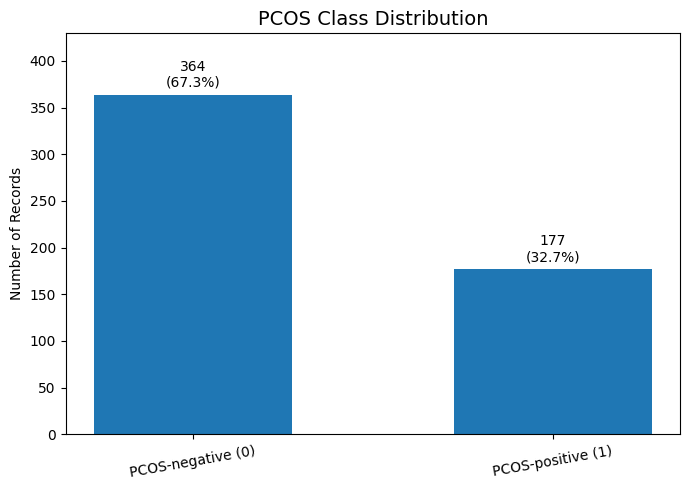

In [3]:

# Exploratory Data Analysis: PCOS target distribution

import matplotlib.pyplot as plt

target_counts = df["PCOS (Y/N)"].value_counts().sort_index()
target_labels = ["PCOS-negative (0)", "PCOS-positive (1)"]
target_percentages = target_counts / target_counts.sum() * 100

print("PCOS class distribution:")
for label, count, percentage in zip(
    target_labels, target_counts.values, target_percentages.values
):
    print(f"{label}: {count} records ({percentage:.1f}%)")

fig, ax = plt.subplots(figsize=(7, 5))

bars = ax.bar(
    target_labels,
    target_counts.values,
    width=0.55,
)

ax.set_title("PCOS Class Distribution", fontsize=14)
ax.set_ylabel("Number of Records")
ax.set_ylim(0, max(target_counts.values) * 1.18)
ax.tick_params(axis="x", rotation=10)

for bar, count, percentage in zip(
    bars, target_counts.values, target_percentages.values
):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 5,
        f"{count}\n({percentage:.1f}%)",
        ha="center",
        va="bottom",
    )

fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / "pcos_class_distribution.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()


Total missing cells: 3

Columns containing missing values:


,Missing Count,Missing Percentage (%)
Marraige Status (Yrs),1,0.18
AMH(ng/mL),1,0.18
Fast food (Y/N),1,0.18


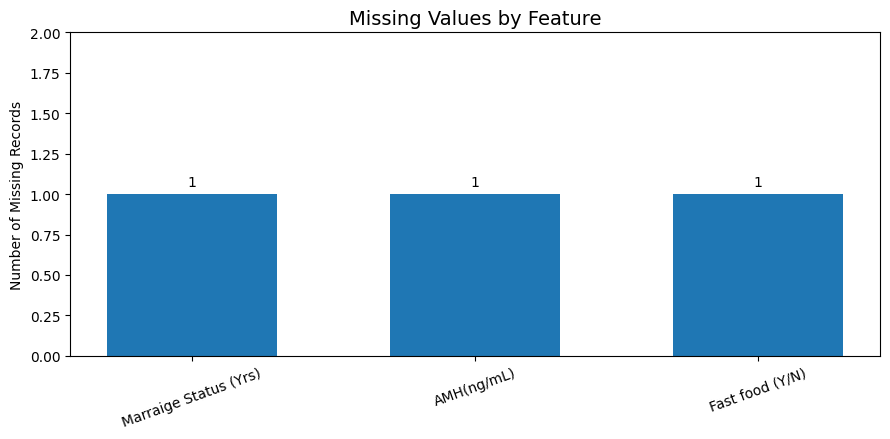

In [4]:

# Exploratory Data Analysis: Missing-value analysis

missing_counts = df.isna().sum()
missing_counts = missing_counts[missing_counts > 0].sort_values(
    ascending=False
)

print("Total missing cells:", int(df.isna().sum().sum()))
print("\nColumns containing missing values:")
if missing_counts.empty:
    print("No missing values found.")
else:
    missing_summary = pd.DataFrame({
        "Missing Count": missing_counts,
        "Missing Percentage (%)": (
            missing_counts / len(df) * 100
        ).round(2),
    })
    display(missing_summary)

    fig, ax = plt.subplots(figsize=(9, 4.5))

    bars = ax.bar(
        missing_counts.index.astype(str),
        missing_counts.values,
        width=0.6,
    )

    ax.set_title("Missing Values by Feature", fontsize=14)
    ax.set_ylabel("Number of Missing Records")
    ax.set_ylim(0, max(missing_counts.values) + 1)
    ax.tick_params(axis="x", rotation=20)

    for bar in bars:
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.03,
            f"{int(bar.get_height())}",
            ha="center",
            va="bottom",
        )

    fig.tight_layout()
    fig.savefig(
        OUTPUT_DIR / "missing_values.png",
        dpi=300,
        bbox_inches="tight",
    )
    plt.show()


In [ ]:

df.columns = df.columns.str.strip()

print([repr(col) for col in df.columns if "Age" in col or "BMI" in col])
      

["'Age (yrs)'", "'BMI'"]


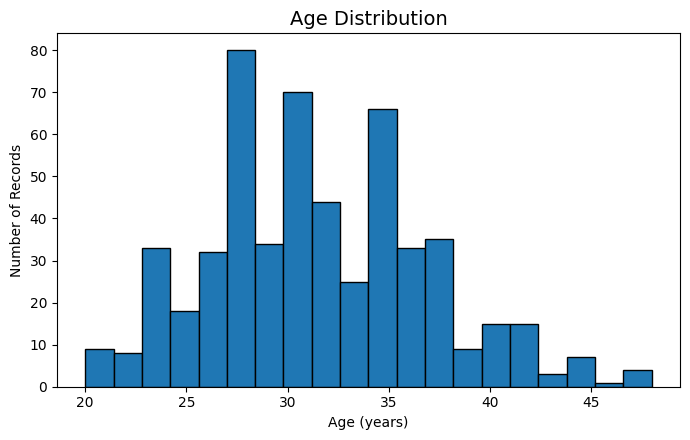

Age (yrs): count=541, mean=31.43, median=31.00, minimum=20.00, maximum=48.00


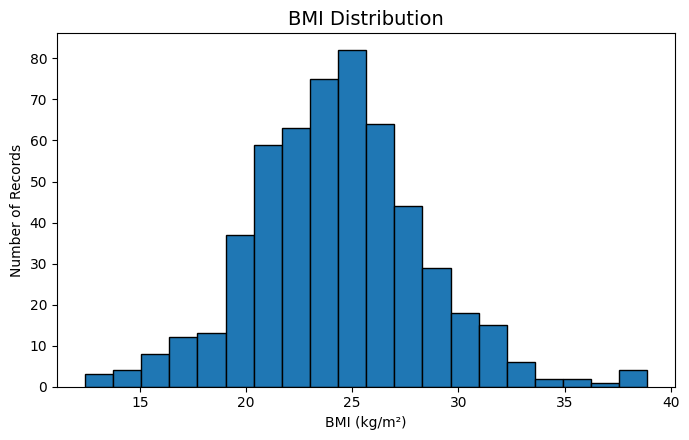

BMI: count=541, mean=24.31, median=24.24, minimum=12.42, maximum=38.90


In [ ]:

# Exploratory Data Analysis: Age and BMI distributions

features = [
    ("Age (yrs)", "Age Distribution", "Age (years)", "age_distribution.png"),
    ("BMI", "BMI Distribution", "BMI (kg/m²)", "bmi_distribution.png"),
]

for column, title, xlabel, filename in features:
    values = pd.to_numeric(df[column], errors="coerce").dropna()

    fig, ax = plt.subplots(figsize=(7, 4.5))
    ax.hist(values, bins=20, edgecolor="black")

    ax.set_title(title, fontsize=14)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Number of Records")

    fig.tight_layout()
    fig.savefig(
        OUTPUT_DIR / filename,
        dpi=300,
        bbox_inches="tight",
    )
    plt.show()

    print(
        f"{column}: count={len(values)}, "
        f"mean={values.mean():.2f}, "
        f"median={values.median():.2f}, "
        f"minimum={values.min():.2f}, "
        f"maximum={values.max():.2f}"
    )


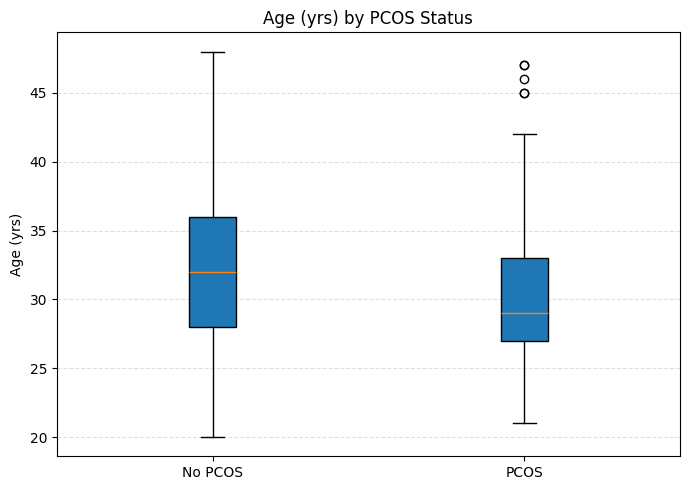

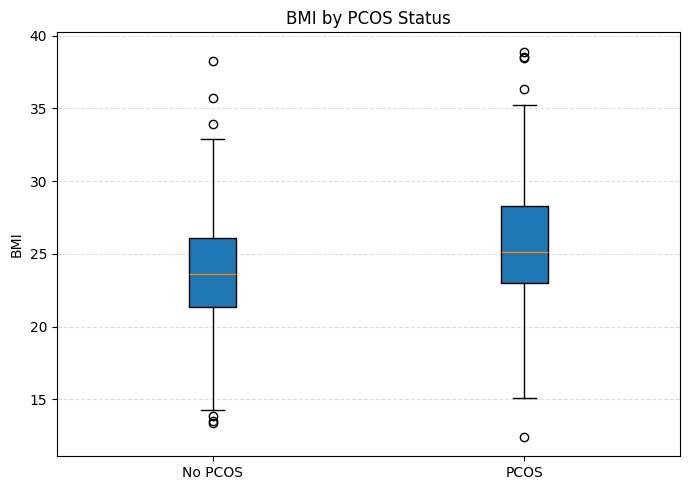

Age and BMI comparison charts saved successfully.


In [ ]:

import matplotlib.pyplot as plt
import pandas as pd

target = "PCOS (Y/N)"
features = ["Age (yrs)", "BMI"]

for column in features:
    df[column] = pd.to_numeric(df[column], errors="coerce")

    groups = [
        df.loc[df[target] == 0, column].dropna(),
        df.loc[df[target] == 1, column].dropna()
    ]

    plt.figure(figsize=(7, 5))
    plt.boxplot(
        groups,
        tick_labels=["No PCOS", "PCOS"],
        patch_artist=True
    )
    plt.title(f"{column} by PCOS Status")
    plt.ylabel(column)
    plt.grid(axis="y", linestyle="--", alpha=0.4)
    plt.tight_layout()

    filename = column.lower().replace(" ", "_").replace("(", "").replace(")", "").replace("/", "_")
    plt.savefig(OUTPUT_DIR / f"{filename}_by_pcos.png", dpi=300)
    plt.show()

print("Age and BMI comparison charts saved successfully.")


Categorical features selected:
['Cycle(R/I)', 'Weight gain(Y/N)', 'hair growth(Y/N)', 'Skin darkening (Y/N)', 'Hair loss(Y/N)', 'Pimples(Y/N)', 'Fast food (Y/N)', 'Reg.Exercise(Y/N)']


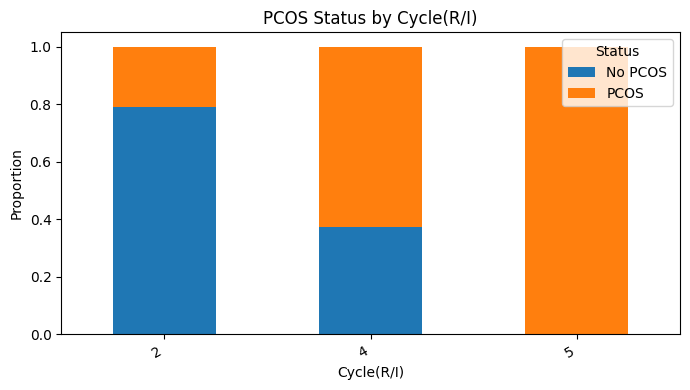

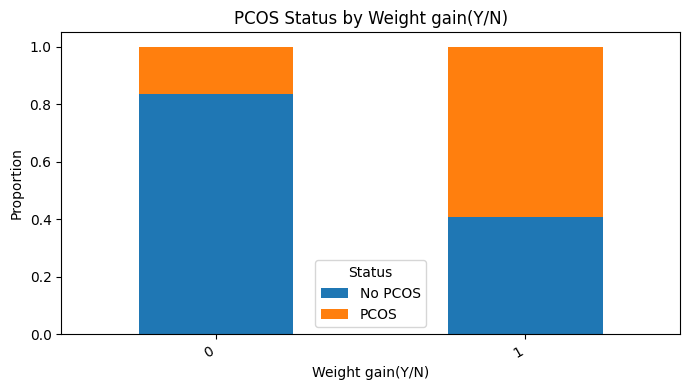

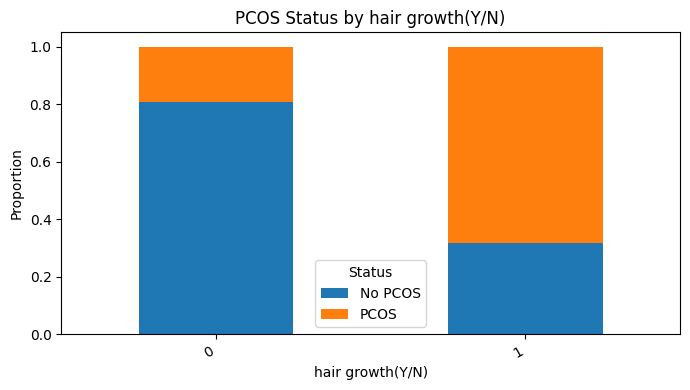

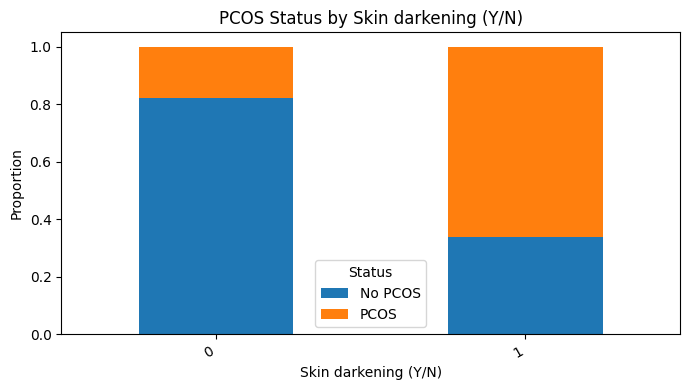

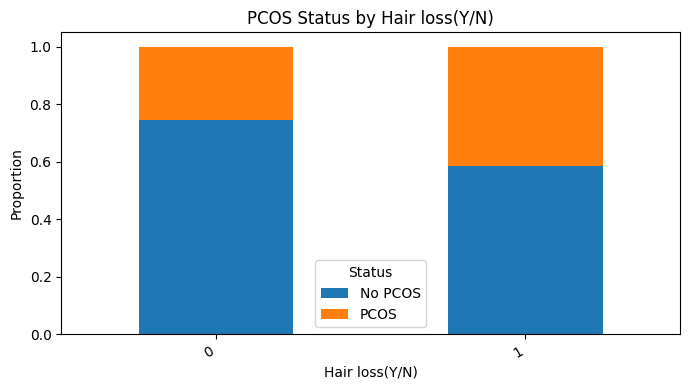

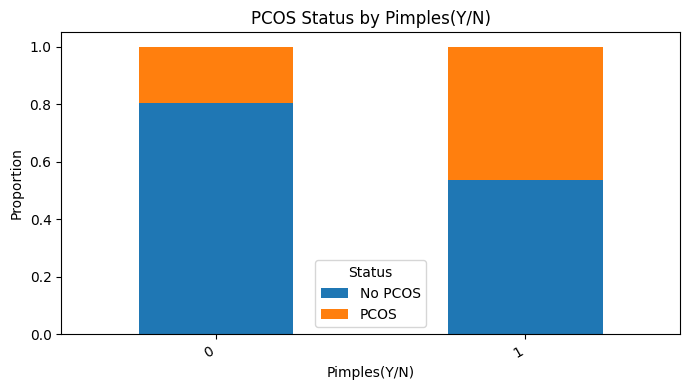

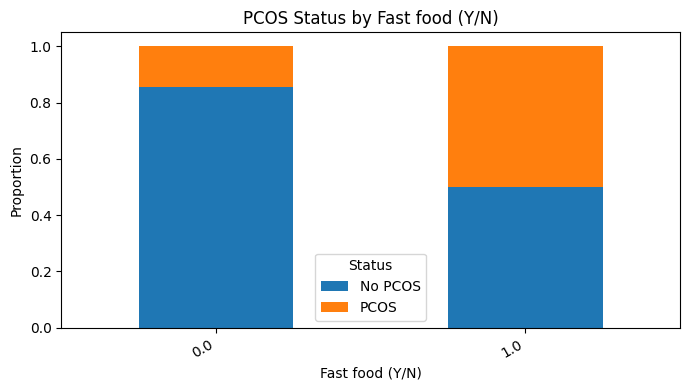

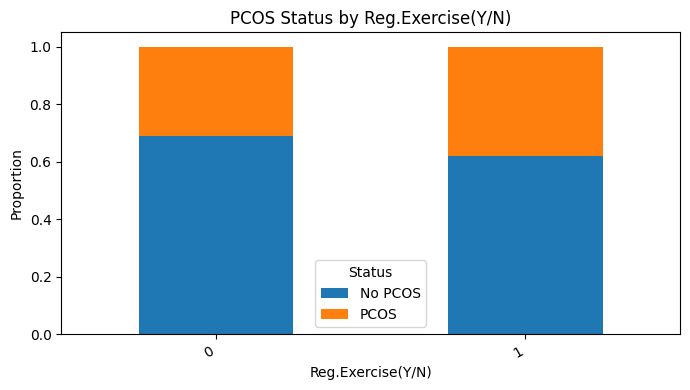

Categorical analysis complete.


In [ ]:

import matplotlib.pyplot as plt
import pandas as pd

target = "PCOS (Y/N)"

# Find likely categorical clinical/lifestyle features
keywords = [
    "cycle", "fast food", "exercise", "skin darkening",
    "hair loss", "hair growth", "pimples", "weight gain"
]

categorical_features = [
    col for col in df.columns
    if col != target
    and any(word in col.lower() for word in keywords)
    and df[col].nunique(dropna=True) <= 10
]

print("Categorical features selected:")
print(categorical_features)

if not categorical_features:
    print("No matching features found. Check the printed column names.")
else:
    for column in categorical_features:
        data = df[[column, target]].dropna().copy()
        data[target] = data[target].astype(int).map({
            0: "No PCOS",
            1: "PCOS"
        })

        proportions = pd.crosstab(
            data[column].astype(str),
            data[target],
            normalize="index"
        )

        proportions.plot(
            kind="bar",
            stacked=True,
            figsize=(7, 4)
        )
        plt.title(f"PCOS Status by {column}")
        plt.xlabel(column)
        plt.ylabel("Proportion")
        plt.xticks(rotation=30, ha="right")
        plt.legend(title="Status")
        plt.tight_layout()

        filename = (
            column.lower()
            .replace(" ", "_")
            .replace("/", "_")
            .replace("(", "")
            .replace(")", "")
        )
        plt.savefig(
            OUTPUT_DIR / f"{filename}_pcos_comparison.png",
            dpi=300
        )
        plt.show()

print("Categorical analysis complete.")


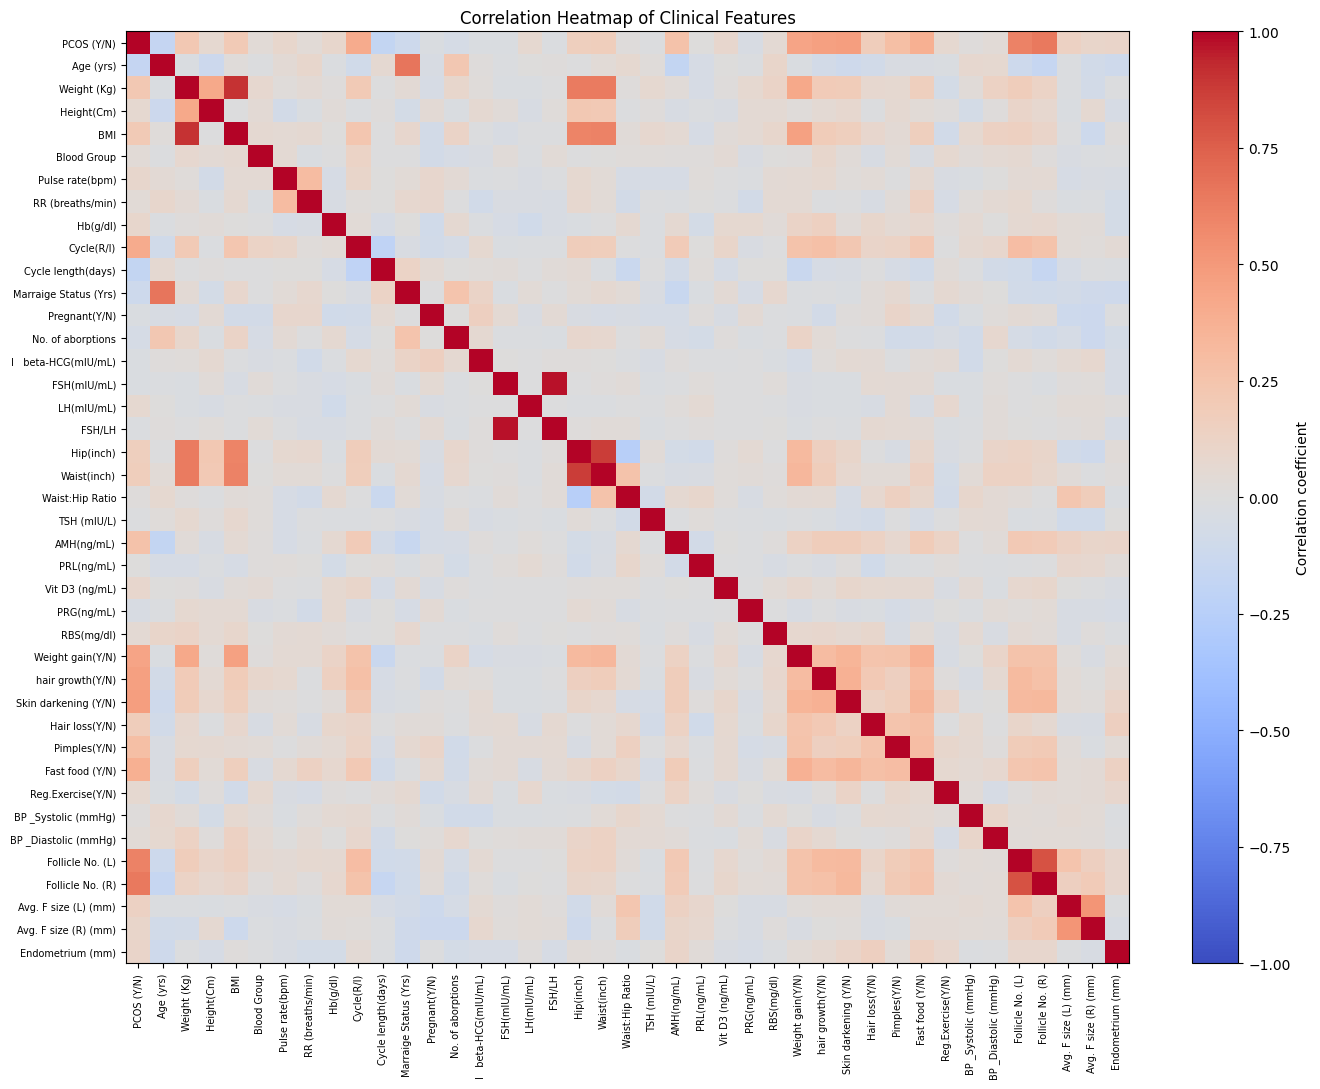

Correlation heatmap saved successfully.


In [ ]:

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Select numeric columns for correlation analysis
numeric_df = df.select_dtypes(include="number")

# Calculate correlations
correlation = numeric_df.corr()

# Plot heatmap
fig, ax = plt.subplots(figsize=(14, 11))

image = ax.imshow(
    correlation,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    aspect="auto"
)

ax.set_xticks(range(len(correlation.columns)))
ax.set_xticklabels(correlation.columns, rotation=90, fontsize=7)
ax.set_yticks(range(len(correlation.columns)))
ax.set_yticklabels(correlation.columns, fontsize=7)

ax.set_title("Correlation Heatmap of Clinical Features")
fig.colorbar(image, ax=ax, label="Correlation coefficient")
plt.tight_layout()

# Save the figure
plt.savefig(
    OUTPUT_DIR / "clinical_correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Correlation heatmap saved successfully.")


In [ ]:

import pandas as pd
from pathlib import Path

target = "PCOS (Y/N)"

audit_rows = []

for column in df.columns:
    examples = (
        df[column]
        .dropna()
        .astype(str)
        .unique()[:5]
        .tolist()
    )

    audit_rows.append({
        "Feature": column,
        "Data Type": str(df[column].dtype),
        "Missing Values": int(df[column].isna().sum()),
        "Unique Values": int(df[column].nunique(dropna=True)),
        "Example Values": ", ".join(examples)
    })

feature_audit = pd.DataFrame(audit_rows)

display(feature_audit)

# Save a local copy for reviewing the model inputs
audit_path = OUTPUT_DIR / "feature_audit.csv"
feature_audit.to_csv(audit_path, index=False)

print(f"\nFeature audit saved to: {audit_path}")
print(f"Total columns: {len(df.columns)}")
print(f"Target column present: {target in df.columns}")
print("\nTarget distribution:")
print(df[target].value_counts(dropna=False).sort_index())


,Feature,Data Type,Missing Values,Unique Values,Example Values
0,PCOS (Y/N),int64,0,2,"0, 1"
1,Age (yrs),int64,0,29,"28, 36, 33, 37, 25"
2,Weight (Kg),float64,0,117,"44.6, 65.0, 68.8, 52.0, 74.1"
3,Height(Cm),float64,0,50,"152.0, 161.5, 165.0, 148.0, 161.0"
4,BMI,float64,0,355,"19.3, 24.92116286, 25.27089073, 29.67494522, 2..."
5,Blood Group,int64,0,8,"15, 11, 13, 17, 16"
6,Pulse rate(bpm),int64,0,11,"78, 74, 72, 80, 70"
7,RR (breaths/min),int64,0,8,"22, 20, 18, 28, 16"
8,Hb(g/dl),float64,0,46,"10.48, 11.7, 11.8, 12.0, 10.0"
9,Cycle(R/I),int64,0,3,"2, 4, 5"



Feature audit saved to: c:\Projects\Mahila-Mitra\outputs\clinical\feature_audit.csv
Total columns: 42
Target column present: True

Target distribution:
PCOS (Y/N)
0    364
1    177
Name: count, dtype: int64


In [ ]:
# Step 8A: Inspect blood pressure values

bp_columns = [
    "BP _Systolic (mmHg)",
    "BP _Diastolic (mmHg)"
]

thresholds = {
    "BP _Systolic (mmHg)": 50,
    "BP _Diastolic (mmHg)": 40,
}

for column in bp_columns:
    print(f"\n{column}")
    print("Sorted unique values:")
    print(sorted(df[column].dropna().unique().tolist()))

    threshold = thresholds[column]
    print(f"\nValues below {threshold}:")
    print(
        df.loc[
            df[column] < threshold,
            [column, "PCOS (Y/N)"]
        ]
    )


BP _Systolic (mmHg)
Sorted unique values:
[12, 100, 110, 120, 130, 140]

Values below a plausible screening threshold:
     BP _Systolic (mmHg)  PCOS (Y/N)
161                   12           0

BP _Diastolic (mmHg)
Sorted unique values:
[8, 60, 70, 80, 100]

Values below a plausible screening threshold:
     BP _Diastolic (mmHg)  PCOS (Y/N)
200                     8           0


In [ ]:
# Inspect records with suspicious blood-pressure values

suspicious_record = df[
    (df["BP _Systolic (mmHg)"] < 50) |
    (df["BP _Diastolic (mmHg)"] < 40)
]

display(suspicious_record.T)

,161,200
PCOS (Y/N),0,0
Age (yrs),38,30
Weight (Kg),70.0,47.0
Height(Cm),170.0,158.0
BMI,24.221453,18.827111
Blood Group,13,15
Pulse rate(bpm),75,73
RR (breaths/min),20,18
Hb(g/dl),12.5,11.2
Cycle(R/I),2,2


In [ ]:

# Inspect suspicious blood-pressure values before cleaning.
# The cleaning rules are applied by scripts/clean_clinical.py.

systolic_col = "BP _Systolic (mmHg)"
diastolic_col = "BP _Diastolic (mmHg)"

print(
    "Systolic values below 50:",
    int((df[systolic_col] < 50).sum())
)
print(
    "Diastolic values below 40:",
    int((df[diastolic_col] < 40).sum())
)

print("\nMissing blood-pressure values:")
print(df[[systolic_col, diastolic_col]].isna().sum())


Suspicious systolic values: 1
Suspicious diastolic values: 1

Missing blood pressure values after cleaning:
BP _Systolic (mmHg)     1
BP _Diastolic (mmHg)    1
dtype: int64

Remaining suspicious values:
Systolic: 0
Diastolic: 0


In [ ]:
# Confirm the dataset currently loaded for exploratory analysis.
print("Dataset shape:", df.shape)

print("\nMissing values by blood-pressure column:")
print(
    df[
        ["BP _Systolic (mmHg)", "BP _Diastolic (mmHg)"]
    ].isna().sum()
)

print("\nTarget distribution:")
print(df["PCOS (Y/N)"].value_counts(dropna=False).sort_index())

Corrected dataset saved to: c:\Projects\Mahila-Mitra\outputs\clinical\clinical_cleaned_corrected.csv
Dataset shape: (541, 42)

Total missing values: 5

Target distribution:
PCOS (Y/N)
0    364
1    177
Name: count, dtype: int64


In [ ]:

target = "PCOS (Y/N)"

print("TARGET COLUMN")
print(target)

print("\nALL PREDICTOR COLUMNS")
for i, column in enumerate(
    [c for c in df.columns if c != target], start=1
):
    print(f"{i:02d}. {column}")

print("\nPOSSIBLE DUPLICATE COLUMNS")
predictors = df.drop(columns=[target])

for column in predictors.columns:
    if predictors[column].equals(df[target]):
        print(f"Exact duplicate of target: {column}")

print("\nIDENTIFIER CHECK")
print("Identifier-like columns still present:")
print([
    c for c in df.columns
    if any(word in c.lower() for word in ["patient file", "serial", "sl. no"])
])


TARGET COLUMN
PCOS (Y/N)

ALL PREDICTOR COLUMNS
01. Age (yrs)
02. Weight (Kg)
03. Height(Cm)
04. BMI
05. Blood Group
06. Pulse rate(bpm)
07. RR (breaths/min)
08. Hb(g/dl)
09. Cycle(R/I)
10. Cycle length(days)
11. Marraige Status (Yrs)
12. Pregnant(Y/N)
13. No. of aborptions
14. I   beta-HCG(mIU/mL)
15. II    beta-HCG(mIU/mL)
16. FSH(mIU/mL)
17. LH(mIU/mL)
18. FSH/LH
19. Hip(inch)
20. Waist(inch)
21. Waist:Hip Ratio
22. TSH (mIU/L)
23. AMH(ng/mL)
24. PRL(ng/mL)
25. Vit D3 (ng/mL)
26. PRG(ng/mL)
27. RBS(mg/dl)
28. Weight gain(Y/N)
29. hair growth(Y/N)
30. Skin darkening (Y/N)
31. Hair loss(Y/N)
32. Pimples(Y/N)
33. Fast food (Y/N)
34. Reg.Exercise(Y/N)
35. BP _Systolic (mmHg)
36. BP _Diastolic (mmHg)
37. Follicle No. (L)
38. Follicle No. (R)
39. Avg. F size (L) (mm)
40. Avg. F size (R) (mm)
41. Endometrium (mm)

POSSIBLE DUPLICATE COLUMNS

IDENTIFIER CHECK
Identifier-like columns still present:
[]


In [6]:
from pathlib import Path
import pandas as pd

raw_path = Path("../data/raw/clinical/PCOS_data_without_infertility.xlsx")
clean_path = Path("../data/processed/clinical_cleaned.csv")

# If notebook paths are relative to the project root, use these instead
if not raw_path.exists():
    raw_path = Path("data/raw/clinical/PCOS_data_without_infertility.xlsx")
if not clean_path.exists():
    clean_path = Path("data/processed/clinical_cleaned.csv")

print("Raw dataset exists:", raw_path.exists())
print("Cleaned dataset exists:", clean_path.exists())

if raw_path.exists() and clean_path.exists():
    raw = pd.read_excel(raw_path, sheet_name="Full_new")
    clean = pd.read_csv(clean_path)

    print("\n--- RAW DATASET ---")
    print("Shape:", raw.shape)
    print("Duplicate rows:", raw.duplicated().sum())

    print("\n--- CLEANED DATASET ---")
    print("Shape:", clean.shape)
    print("Duplicate rows:", clean.duplicated().sum())
    print("Target values:", sorted(clean["PCOS (Y/N)"].dropna().unique()))
    print("\nTarget distribution:")
    print(clean["PCOS (Y/N)"].value_counts(dropna=False))
    print("\nMissing values:")
    print(clean.isna().sum()[clean.isna().sum() > 0])
else:
    print("\nFile path not found. Check the project folder paths.")

Raw dataset exists: True
Cleaned dataset exists: True

--- RAW DATASET ---
Shape: (541, 45)
Duplicate rows: 0

--- CLEANED DATASET ---
Shape: (541, 42)
Duplicate rows: 0
Target values: [0, 1]

Target distribution:
PCOS (Y/N)
0    364
1    177
Name: count, dtype: int64

Missing values:
Marraige Status (Yrs)    1
AMH(ng/mL)               1
Fast food (Y/N)          1
dtype: int64
